## Assignment 8: Using Unsupervised Machine Learning to Discover Climate Zones

In this homework assignment, you will explore some common clustering methods, including K-Means clustering and Gaussian Mixture Models. 

You'll apply these clustering algorithms to the problem of classifying climate zones over the continental United States. The Köppen-Geiger Climate Zones are a climate classification system based on precipitation and temperature (https://www.noaa.gov/jetstream/global/climate-zones/jetstream-max-addition-k-ppen-geiger-climate-subdivisions). You'll use unsupervised machine learning to discover similar climate zones using the climatological averages for temperature and precipitation.

## The data sets
You'll use climatological data over the continental US, specifically average monthly precipitation and temperature records for the years 1901 to 2000 from NOAA that can be found [here](https://www.ncei.noaa.gov/products/land-based-station/us-climate-normals). The code in question 1 downloads the two NetCDF files the first time you run it and saves them next to this notebook. After that it skips the download.

## Part 1: Load and prepare the climatological data

1) The code below is given. Run it to download the NetCDF files for the climatological temperature and precipitation datasets for the continental US, if they are not already in this folder, and open them with `xarray`. The download can take a few minutes.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# Download once if the files are not already alongside this notebook.
import os, urllib.request
BASE = ("https://www.ncei.noaa.gov/data/oceans/archive/arc0196/0248762/1.1/"
        "data/0-data/")
for fname in ["tavg-1901_2000-monthly-normals-v1.0.nc",
              "prcp-1901_2000-monthly-normals-v1.0.nc"]:
    if not os.path.exists(fname):
        print("downloading", fname, "(268 MB)...")
        urllib.request.urlretrieve(BASE + fname, fname)

temp = xr.open_dataset("tavg-1901_2000-monthly-normals-v1.0.nc")
prec = xr.open_dataset("prcp-1901_2000-monthly-normals-v1.0.nc")

downloading tavg-1901_2000-monthly-normals-v1.0.nc (268 MB)...
downloading prcp-1901_2000-monthly-normals-v1.0.nc (268 MB)...


In [8]:
prec.info()
# mlyprcp_norm(time, lat, lon) Monthly Precipitation is stored in a 3D array. Specifying a month gives the other 2 dimensions for the month.

xarray.Dataset {
dimensions:
	lon = 1385 ;
	lat = 596 ;
	time = 12 ;
	seasons = 4 ;

variables:
	float32 lon(lon) ;
		lon:long_name = longitude ;
		lon:standard_name = longitude ;
		lon:units = degrees_east ;
		lon:axis = X ;
		lon:valid_min = -124.6875f ;
		lon:valid_max = -67.02084f ;
		lon:comment = Resolution is 1/24 degree, equivalent to 4.63 km at the Equator, and ranging from 4.21 km at the southern boundary of 24.5625 deg. N to 3.02 km at 49.3542 deg. N ;
	float32 lat(lat) ;
		lat:long_name = Latitude ;
		lat:standard_name = Latitude ;
		lat:units = degrees_north ;
		lat:axis = Y ;
		lat:valid_min = 24.56253f ;
		lat:valid_max = 49.3542f ;
		lat:comment = Resolution is 1/24 degree, equivalent to 4.63 km; range is 24.5625 to 49.3542 degrees north ;
	int32 time(time) ;
		time:long_name = Time, month of the year ;
		time:standard_name = time ;
		time:calendar = gregorian ;
		time:units = months ;
		time:axis = T ;
		time:comment = A month is defined between 1 and 12 ;
	int32 seaso

2) Make a plot of the monthly average precipitation in January over the Continental US.

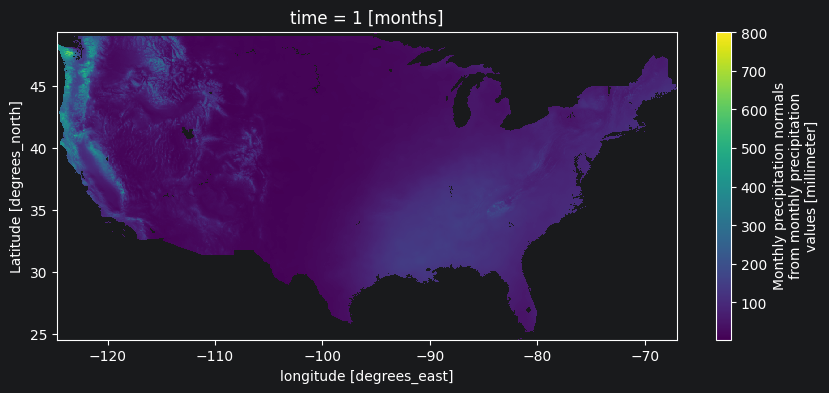

In [11]:
jan_prec = prec['mlyprcp_norm'].sel(time = 1)
fig, ax = plt.subplots(figsize=(10,4))
jan_prec.squeeze().plot(ax=ax, cmap='viridis')
plt.show()

3. Make a plot of the monthly average temperature in August over the Continent US.

In [12]:
temp.info()

xarray.Dataset {
dimensions:
	lon = 1385 ;
	lat = 596 ;
	time = 12 ;
	seasons = 4 ;

variables:
	float32 lon(lon) ;
		lon:long_name = longitude ;
		lon:standard_name = longitude ;
		lon:units = degrees_east ;
		lon:axis = X ;
		lon:valid_min = -124.6875f ;
		lon:valid_max = -67.02084f ;
		lon:comment = Resolution is 1/24 degree, equivalent to 4.63 km at the Equator, and ranging from 4.21 km at the southern boundary of 24.5625 deg. N to 3.02 km at 49.3542 deg. N ;
	float32 lat(lat) ;
		lat:long_name = Latitude ;
		lat:standard_name = Latitude ;
		lat:units = degrees_north ;
		lat:axis = Y ;
		lat:valid_min = 24.56253f ;
		lat:valid_max = 49.3542f ;
		lat:comment = Resolution is 1/24 degree, equivalent to 4.63 km; range is 24.5625 to 49.3542 degrees north ;
	int32 time(time) ;
		time:long_name = Time, month of the year ;
		time:standard_name = time ;
		time:calendar = gregorian ;
		time:units = months ;
		time:axis = T ;
		time:comment = A month is defined between 1 and 12 ;
	int32 seaso

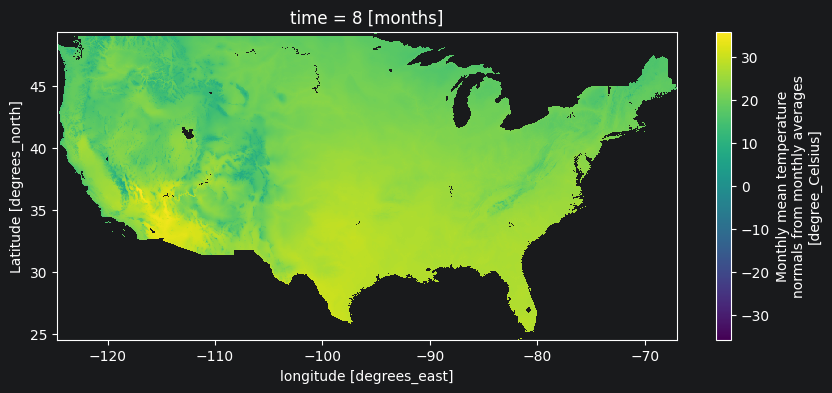

In [14]:
aug_temp = temp['mlytavg_norm'].sel(time = 8)
fig, ax = plt.subplots(figsize=(10,4))
aug_temp.squeeze().plot(ax=ax, cmap='viridis')
plt.show()

To identify climatological zones across the continental US, you will use the 12 monthly average temperature values and the 12 monthly average precipitation values as input features for clustering algorithms. Each latitude and longitude point will be treated as a single sample with 24 features (12 for temperature and 12 for precipitation).

4) First, extract the values for "mlytavg_norm" from the temperature and precipitation NetCDF files and store them in NumPy arrays named `avgtemp` and `avgprec`, respectively.

In [15]:
avgtemp = temp['mlytavg_norm'].values
avgprec = prec['mlyprcp_norm'].values

print(avgtemp.shape)
print(avgprec.shape)

(12, 596, 1385)
(12, 596, 1385)


5. Put the latitude and longitude values into numpy arrays, and use the `np.meshgrid` function to create a 2D array that gives the latitude and longitude value at each point on the map:
~~~
lat_grid, lon_grid = np.meshgrid(lats, lons, indexing="ij")
~~~
You'll use these arrays later to create labels for the latitude and longitude points associated with each sample.

In [16]:
lats = temp['lat'].values
lons = temp['lon'].values

lat_grid, lon_grid = np.meshgrid(lats, lons, indexing="ij")

6. Use the `np.isnan` function to create a mask that gives a value of 1 where there is data and a value of 0 where there is no data in the 2D array of the precipitation and temperature maps over the continental US. This mask should have the same dimensions as latitude by longitude. Hint: `np.isnan` returns 1 (True) if the value is `NaN`. 

In [33]:
temp_nan = np.isnan(avgtemp)
prec_nan = np.isnan(avgprec)

mask = ~(temp_nan.any(axis=0) | prec_nan.any(axis=0)) # Mask is for not temp nan and not prec nan ie. actual value for prec and temp
print(f"{100 * mask.sum()/(596*1385):.2f}% is masked")
avgtemp.shape


56.91% is masked


(12, 596, 1385)

7. Use the mask to index the numpy arrays of `avgtemp`, `avgprec`, `lat_grid`, and `lon_grid` to create arrays called `avgtemp_masked`, `avgprec_masked`, `lat_masked`, and `lon_masked`. These arrays now should no longer have any NaN's.

In [27]:
avgtemp_masked = avgtemp[:, mask]
avgprec_masked = avgprec[:, mask]
lat_masked = lat_grid[mask]
lon_masked = lon_grid[mask]

8. `sci-kit learn` functions assume that the sample number ($n_{sample}$) is the first dimension in an array, and the features associated with a sample are in the second dimension in an array. Transpose the `avgprec_masked` and `avgtemp_masked` to get the correct ordering of dimensions. Check the shape of the arrays are now $n_{sample}$ x 12.

In [34]:
avgtemp_masked = avgtemp_masked.T
avgprec_masked = avgprec_masked.T
print(avgtemp_masked.shape)
print(avgprec_masked.shape)


(469758, 12)
(469758, 12)


## Part 2: Pre-process the data

9. Scale the precipitation and temperature arrays between -1 and 1. You want to do this so that all 12 months are scaled relative to the same minimum and maximum values for precipitation or temperature, respectively. You can use the `MinMaxScaler` from `sci-kit learn` (you will have to reshape the arrays to do this) or alternatively write your own function to do this scaling.

In [36]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1,1))

# reshape(-1,1) makes the shape (n_samples x 12, 1), moving all values into one column so the scaler can see everything in a single feature
# the second reshape(avgtemp_masked.shape) makes the shape (n_samples, 12) back to how it was
avgtemp_masked_scaled = min_max_scaler.fit_transform(avgtemp_masked.reshape(-1, 1)).reshape(avgtemp_masked.shape)
avgprec_masked_scaled = min_max_scaler.fit_transform(avgprec_masked.reshape(-1, 1)).reshape(avgprec_masked.shape)

10. Create a feature array `X` that is $n_{samples}$ by $n_{features}$, where $n_{features}$=24 (i.e. it combines the two arrays that contain the scaled temperature and precipitation monthly averages associated with each sample).

In [37]:
X = np.concatenate([avgtemp_masked_scaled, avgprec_masked_scaled], axis = 1)

## Part 3: Use K-Means Clustering to Label Climate Zones

11. Use the `KMeans` method from `sklearn.cluster` to fit 8 clusters to the `X` feature matrix.

In [39]:
from sklearn.cluster import KMeans
km = KMeans(n_clusters=8, n_init=10, random_state=27).fit(X)

/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

12. Make a scatter plot of `lat_masked` vs. `lon_masked` and color each point by its kmeans label. Set the size of the points in the scatter points to 0.1 and use a colormap that is discrete (rather than continuous).

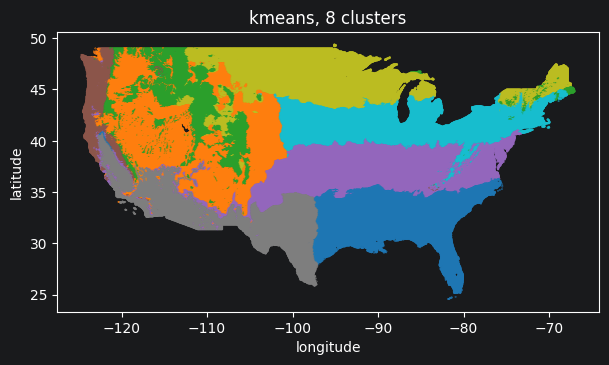

In [44]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(lon_masked, lat_masked, c=km.labels_, s=0.1, cmap=plt.cm.tab10)
ax.set(title='kmeans, 8 clusters', xlabel="longitude", ylabel="latitude", aspect=1.2)
plt.show()

You can compare the climate zones discovered by the K-Means clustering approach with the map [here](https://www.cec.org/mapmonday/climate-zones-in-north-america/).

13. Repeat parts 11. and 12. but choose a different number of clusters to fit Kmeans. 

/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

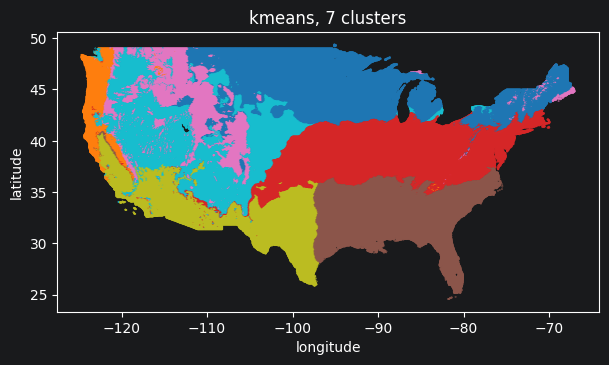

In [46]:
km2 = KMeans(n_clusters=7, n_init=10, random_state=27).fit(X)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(lon_masked, lat_masked, c=km2.labels_, s=0.1, cmap=plt.cm.tab10)
ax.set(title='kmeans, 7 clusters', xlabel="longitude", ylabel="latitude", aspect=1.2)
plt.show()

/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

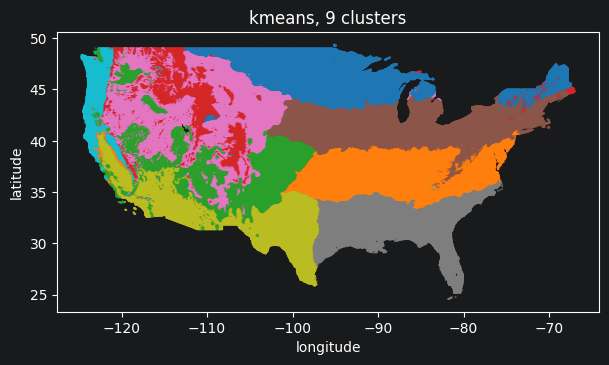

In [47]:
km3 = KMeans(n_clusters=9, n_init=10, random_state=27).fit(X)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(lon_masked, lat_masked, c=km3.labels_, s=0.1, cmap=plt.cm.tab10)
ax.set(title='kmeans, 9 clusters', xlabel="longitude", ylabel="latitude", aspect=1.2)
plt.show()

## Part 4: Use a Gaussian Mixture Model to Label Climate Zones

14. Use the `GaussianMixture` method from `sklearn.mixture` to fit 8 components to the `X` feature matrix.

In [48]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=8, n_init=5, random_state=27).fit(X)
gm_labels = gm.predict(X)

/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

15.  Make a scatter plot of `lat_masked` vs. `lon_masked` and color by the components learned by the Gaussian Mixture Model. Set the size of the scatter points to 0.1 and use a colormap that is discrete (rather than continuous).

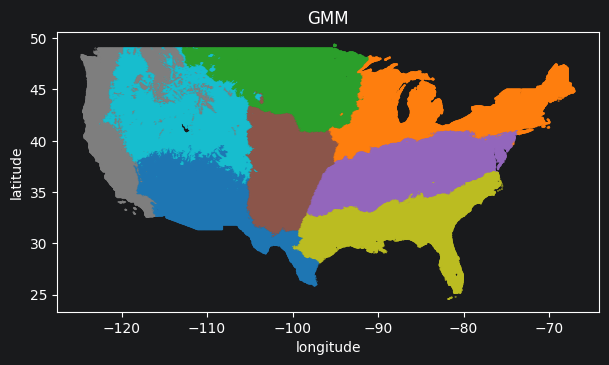

In [49]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(lon_masked, lat_masked, c=gm_labels, s=0.1, cmap=plt.cm.tab10)
ax.set(title='GMM', xlabel="longitude", ylabel="latitude", aspect=1.2)
plt.show()